# Smart Waste Sorter · 04 Vision Transformers

**Week 4 milestone.** Is a Vision Transformer better than a CNN for sorting waste, and how much labelled
data does each need? Lecture 4 said ViTs have weak inductive bias, so they should suffer more when data is
scarce. Test that claim.

- **Part A:** a pretrained ViT-Small (patch 16, 224 × 224)
- **Part B:** ViT vs ResNet-18 trained on 10%, 50% and 100% of the training split
- **Part C:** attention maps

Runtime → **T4 GPU**. Run `00_setup_and_data` first. Part B trains six models: about 15 minutes on a T4.

In [ ]:
import os, sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
ROOT = os.environ.get("WS_ROOT") or ("/content/drive/MyDrive/waste_sorter" if IN_COLAB else "./waste_sorter")
sys.path.insert(0, ROOT)
import ws_utils as ws
ws.setup(team="NIYOMUGENGA Marie Claire")

import numpy as np, pandas as pd, torch, torch.nn as nn, timm
import matplotlib.pyplot as plt
from torchvision.models import resnet18, ResNet18_Weights
dev = ws.device()
PRETRAINED = not ws.SMOKE

Mounted at /content/drive
Copying data from Drive to the local disk (once per session)...
Team: NIYOMUGENGA Marie Claire | root: /content/drive/MyDrive/waste_sorter | device: cuda | smoke test: False


## Part A · The ViT

**TODO 1.** Create `vit_small_patch16_224.augreg_in21k_ft_in1k` with `timm.create_model`, using
`pretrained=PRETRAINED` and `num_classes` set to our six classes (timm replaces the head for you).
Then print: the number of parameters, the number of patches for a 224 × 224 image, and the token sequence
length including the [CLS] token. Check them against the lecture (196 patches, 197 tokens).

This ViT was pretrained with pixels scaled to [−1, 1], so its loaders use `normalize="tanh"`.

In [ ]:
VIT_NAME = "vit_small_patch16_224.augreg_in21k_ft_in1k"

def make_vit():
    return timm.create_model(VIT_NAME, pretrained=PRETRAINED, num_classes=len(ws.CLASSES))

def make_resnet18():
    m = resnet18(weights=ResNet18_Weights.DEFAULT if PRETRAINED else None)
    m.fc = nn.Linear(m.fc.in_features, len(ws.CLASSES))
    return m

vit = make_vit()

n_params = ws.count_params(vit)
n_patches = vit.patch_embed.num_patches
with torch.no_grad():
    tokens = vit.forward_features(torch.randn(1, 3, 224, 224))
print(f"parameters: {n_params:.2f} M")
print(f"patches for a 224x224 image: {n_patches}")
print(f"token sequence: {tuple(tokens.shape)}  ->  {tokens.shape[1]} tokens including [CLS]")

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

parameters: 21.67 M
patches for a 224x224 image: 196
token sequence: (1, 197, 384)  ->  197 tokens including [CLS]


## Part B · How much data does each model need?

**TODO 2.** For each fraction in `FRACTIONS` and each model in `MODELS`: reset the seed, build the model,
make loaders with `train_fraction=frac`, train with `ws.train_classifier` for `ws.epochs(8)` epochs at the
model's learning rate, evaluate on the test set (and local photos), log the result with
`ws.log_result(4, name, test, local, train_fraction=frac, ...)`, and append a row to `rows`.
Everything except the model must stay identical between the two models.

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 189MB/s]



=== ResNet-18 fine-tuned | 10% of the training data (178 images) ===
epoch 1/8  train loss 1.177  val acc 0.588  val macro-F1 0.454
epoch 2/8  train loss 0.281  val acc 0.615  val macro-F1 0.507
epoch 3/8  train loss 0.096  val acc 0.704  val macro-F1 0.601
epoch 4/8  train loss 0.049  val acc 0.760  val macro-F1 0.677
epoch 5/8  train loss 0.024  val acc 0.773  val macro-F1 0.721
epoch 6/8  train loss 0.015  val acc 0.770  val macro-F1 0.707
epoch 7/8  train loss 0.010  val acc 0.784  val macro-F1 0.733
epoch 8/8  train loss 0.010  val acc 0.778  val macro-F1 0.728
Logged: {'method': 'ResNet-18 fine-tuned', 'test_accuracy': '0.7652', 'test_macro_f1': '0.7272', 'trash_f1': '0.4667', 'local_accuracy': '0.3500'}

=== ViT-Small fine-tuned | 10% of the training data (178 images) ===
epoch 1/8  train loss 1.603  val acc 0.583  val macro-F1 0.468
epoch 2/8  train loss 0.503  val acc 0.718  val macro-F1 0.610
epoch 3/8  train loss 0.199  val acc 0.770  val macro-F1 0.698
epoch 4/8  train los

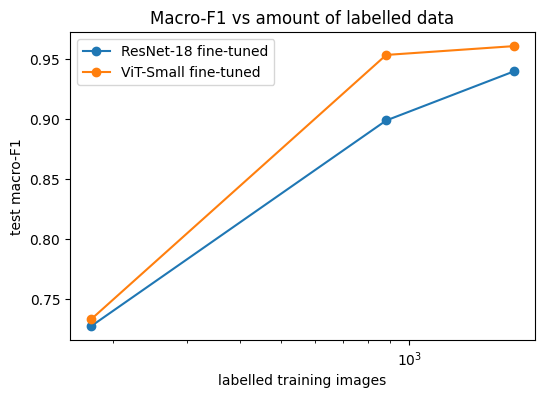

In [ ]:
FRACTIONS = [0.1, 0.5, 1.0]
MODELS = {  # name: (constructor, learning rate, normalisation)
    "ResNet-18 fine-tuned": (make_resnet18, 3e-4, "imagenet"),
    "ViT-Small fine-tuned": (make_vit, 5e-5, "tanh"),
}
rows, trained = [], {}
local_loaders = {norm: ws.local_test_loader(224, normalize=norm) for norm in ["imagenet", "tanh"]}
for frac in FRACTIONS:
    for name, (ctor, lr, norm) in MODELS.items():
        ws.seed_everything()
        model = ctor()
        train_dl, val_dl, test_dl = ws.make_loaders(img_size=224, batch_size=32, train_fraction=frac, normalize=norm)
        n_img = len(train_dl.dataset)
        print(f"\n=== {name} | {int(frac * 100)}% of the training data ({n_img} images) ===")
        minutes = ws.train_classifier(model, train_dl, val_dl, n_epochs=ws.epochs(8), lr=lr)
        test = ws.evaluate(model, test_dl)
        local_dl = local_loaders[norm]
        local = ws.evaluate(model, local_dl) if local_dl else None
        ws.log_result(4, name, test, local, train_fraction=frac, params_millions=ws.count_params(model),
                      train_minutes=minutes, notes=f"{n_img} training images")
        rows.append({"model": name, "fraction": frac, "images": n_img, "accuracy": test["accuracy"],
                     "macro_f1": test["macro_f1"], "trash_f1": test["trash_f1"],
                     "local_acc": local["accuracy"] if local else np.nan,
                     "minutes": minutes, "params_M": ws.count_params(model)})
        trained[(name, frac)] = model
res = pd.DataFrame(rows)
print(res.round(3))

fig, ax = plt.subplots(figsize=(6, 4))
for name, g in res.groupby("model"):
    ax.plot(g.images, g.macro_f1, marker="o", label=name)
ax.set_xlabel("labelled training images"); ax.set_ylabel("test macro-F1"); ax.set_xscale("log")
ax.set_title("Macro-F1 vs amount of labelled data"); ax.legend()
ws.save_figure(fig, "vit_vs_resnet_data.png"); plt.show()

## Part C · Where does the ViT look?
We record the attention weights of the **last** transformer block with a forward hook, then look at how much
the [CLS] token attends to each of the 196 patches.

**TODO 3.** `attn` has shape (batch, heads, 197, 197). Take the row for the [CLS] token (index 0), drop the
[CLS] column, average over heads, and reshape to a 14 × 14 grid, one map per image.

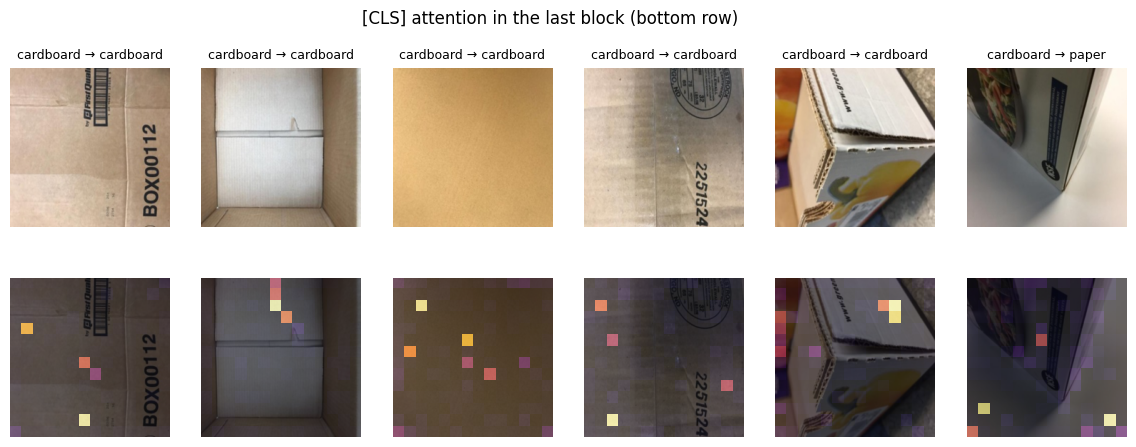

In [ ]:
vit_full = trained[("ViT-Small fine-tuned", 1.0)].eval()
captured = {}
last = vit_full.blocks[-1].attn
last.fused_attn = False                      # use the explicit softmax(QK^T/sqrt(d)) path so we can read it
hook = last.attn_drop.register_forward_hook(lambda m, i, o: captured.__setitem__("attn", o.detach()))

_, _, test_dl = ws.make_loaders(img_size=224, batch_size=6, normalize="tanh")
x, y = next(iter(test_dl))
with torch.no_grad():
    pred = vit_full(x.to(dev)).argmax(1).cpu()
hook.remove()
attn = captured["attn"].cpu()
cls_attn = attn[:, :, 0, 1:]                                   # CLS row, drop the CLS column: (batch, heads, 196)
cls_maps = cls_attn.mean(dim=1).reshape(-1, 14, 14).numpy()    # average over heads, 14x14 grid per image

fig, axes = plt.subplots(2, len(x), figsize=(2.4 * len(x), 5))
for i in range(len(x)):
    img = (x[i] * 0.5 + 0.5).clamp(0, 1).permute(1, 2, 0)
    axes[0, i].imshow(img); axes[0, i].set_title(f"{ws.CLASSES[y[i]]} → {ws.CLASSES[pred[i]]}", fontsize=9)
    axes[1, i].imshow(img); axes[1, i].imshow(cls_maps[i], cmap="inferno", alpha=0.6, extent=(0, 224, 224, 0))
    axes[0, i].axis("off"); axes[1, i].axis("off")
plt.suptitle("[CLS] attention in the last block (bottom row)"); ws.save_figure(fig, "vit_attention.png"); plt.show()



 Stretch

Train a tiny ViT **from scratch** (`timm.create_model("vit_tiny_patch16_224", pretrained=False, num_classes=6)`)
for 20 epochs and compare it with your small CNN from week 1. What does this say about inductive bias?


In [ ]:
ws.seed_everything()
vit_tiny = timm.create_model("vit_tiny_patch16_224", pretrained=False, num_classes=len(ws.CLASSES))
tr, va, te = ws.make_loaders(img_size=224, batch_size=32, normalize="tanh")
minutes = ws.train_classifier(vit_tiny, tr, va, n_epochs=ws.epochs(20), lr=5e-4)
test_t = ws.evaluate(vit_tiny, te)
local_t = ws.evaluate(vit_tiny, local_loaders["tanh"]) if local_loaders["tanh"] else None
print(f"ViT-Tiny from scratch: acc {test_t['accuracy']:.3f}  macro-F1 {test_t['macro_f1']:.3f}  "
      f"trash F1 {test_t['trash_f1']:.3f}  params {ws.count_params(vit_tiny):.2f} M  {minutes:.1f} min")
ws.log_result(4, "ViT-Tiny from scratch", test_t, local_t, params_millions=ws.count_params(vit_tiny),
              train_minutes=minutes, notes="no pretraining, 20 epochs, lr 5e-4")

epoch 1/20  train loss 1.585  val acc 0.385  val macro-F1 0.316
epoch 2/20  train loss 1.480  val acc 0.404  val macro-F1 0.332
epoch 3/20  train loss 1.420  val acc 0.401  val macro-F1 0.313
epoch 4/20  train loss 1.381  val acc 0.449  val macro-F1 0.366
epoch 5/20  train loss 1.328  val acc 0.446  val macro-F1 0.371
epoch 6/20  train loss 1.210  val acc 0.554  val macro-F1 0.508
epoch 7/20  train loss 1.147  val acc 0.549  val macro-F1 0.498
epoch 8/20  train loss 1.075  val acc 0.599  val macro-F1 0.501
epoch 9/20  train loss 1.050  val acc 0.617  val macro-F1 0.545
epoch 10/20  train loss 0.982  val acc 0.580  val macro-F1 0.512
epoch 11/20  train loss 0.898  val acc 0.588  val macro-F1 0.504
epoch 12/20  train loss 0.845  val acc 0.636  val macro-F1 0.544
epoch 13/20  train loss 0.760  val acc 0.697  val macro-F1 0.672
epoch 14/20  train loss 0.684  val acc 0.697  val macro-F1 0.671
epoch 15/20  train loss 0.628  val acc 0.718  val macro-F1 0.682
epoch 16/20  train loss 0.562  val

Misclassified Test Images



misclassified test indices: [ 5 48] | total errors: 12


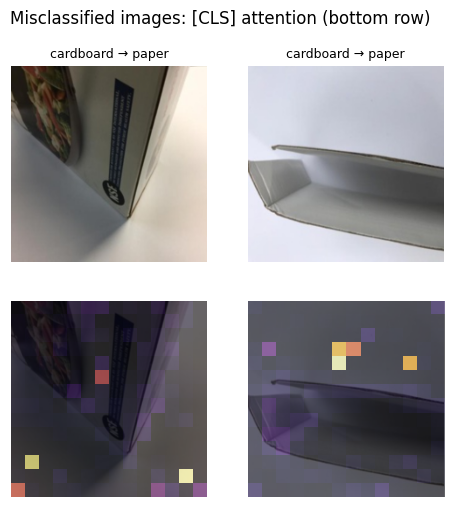

In [ ]:
from PIL import Image
test_dl2 = ws.make_loaders(img_size=224, batch_size=32, normalize="tanh")[2]
m = ws.evaluate(vit_full, test_dl2)
y_true, y_pred = np.array(m["y_true"]), np.array(m["y_pred"])
wrong = np.where(y_true != y_pred)[0][:2]
print("misclassified test indices:", wrong, "| total errors:", int((y_true != y_pred).sum()))

split = ws.load_split()
test_paths = split[split.split == "test"].path.tolist()
tf = ws.transforms_for(224, False, "tanh")
xw = torch.stack([tf(Image.open(test_paths[i]).convert("RGB")) for i in wrong])

captured = {}
hook = last.attn_drop.register_forward_hook(lambda mod, i, o: captured.__setitem__("attn", o.detach()))
with torch.no_grad():
    pw = vit_full(xw.to(dev)).argmax(1).cpu()
hook.remove()
maps = captured["attn"].cpu()[:, :, 0, 1:].mean(1).reshape(-1, 14, 14).numpy()

fig, axes = plt.subplots(2, len(wrong), figsize=(2.8 * len(wrong), 5.6))
for j in range(len(wrong)):
    img = (xw[j] * 0.5 + 0.5).clamp(0, 1).permute(1, 2, 0)
    axes[0, j].imshow(img); axes[0, j].set_title(f"{ws.CLASSES[y_true[wrong[j]]]} → {ws.CLASSES[pw[j]]}", fontsize=9)
    axes[1, j].imshow(img); axes[1, j].imshow(maps[j], cmap="inferno", alpha=0.6, extent=(0, 224, 224, 0))
    axes[0, j].axis("off"); axes[1, j].axis("off")
plt.suptitle("Misclassified images: [CLS] attention (bottom row)")
ws.save_figure(fig, "vit_attention_errors.png"); plt.show()

In [ ]:
from collections import Counter
bad = y_true != y_pred
pairs = Counter((ws.CLASSES[t], ws.CLASSES[p]) for t, p in zip(y_true[bad], y_pred[bad]))
for (t, p), n in pairs.most_common():
    print(f"{t} → {p}: {n}")

cardboard → paper: 3
trash → paper: 2
glass → metal: 1
glass → plastic: 1
paper → plastic: 1
paper → trash: 1
paper → cardboard: 1
plastic → glass: 1
trash → plastic: 1


In [ ]:
 cb, pp = ws.CLASSES.index("cardboard"), ws.CLASSES.index("paper")
 import io, contextlib
def run_vit(seed, augment):
    ws.seed_everything(seed)
    model = make_vit()
    tr, va, te = ws.make_loaders(img_size=224, batch_size=32, augment=augment, normalize="tanh")
    with contextlib.redirect_stdout(io.StringIO()):
        ws.train_classifier(model, tr, va, n_epochs=ws.epochs(8), lr=5e-5)
    m = ws.evaluate(model, te)
    yt, yp = np.array(m["y_true"]), np.array(m["y_pred"])
    return model, dict(seed=seed, augment=augment, acc=m["accuracy"], macro_f1=m["macro_f1"],
                       errors=int((yt != yp).sum()), card_to_paper=int(((yt == cb) & (yp == pp)).sum()))

out, aug_model = [], None
for s in [0, 1, 2]:
    for aug in [False, True]:
        model, r = run_vit(s, aug)
        out.append(r); print(r)
        if aug and s == 0: aug_model = model
df = pd.DataFrame(out)
print(df.groupby("augment")[["acc", "macro_f1", "errors", "card_to_paper"]].agg(["mean", "std"]).round(3))

{'seed': 0, 'augment': False, 'acc': 0.9604221635883905, 'macro_f1': 0.9546299282509151, 'errors': 15, 'card_to_paper': 2}
{'seed': 0, 'augment': True, 'acc': 0.9551451187335093, 'macro_f1': 0.9449613050789414, 'errors': 17, 'card_to_paper': 3}
{'seed': 1, 'augment': False, 'acc': 0.9551451187335093, 'macro_f1': 0.9428517759477195, 'errors': 17, 'card_to_paper': 4}
{'seed': 1, 'augment': True, 'acc': 0.9551451187335093, 'macro_f1': 0.9383947934549289, 'errors': 17, 'card_to_paper': 2}
{'seed': 2, 'augment': False, 'acc': 0.9709762532981531, 'macro_f1': 0.9666223693664326, 'errors': 11, 'card_to_paper': 3}
{'seed': 2, 'augment': True, 'acc': 0.9656992084432717, 'macro_f1': 0.9602506097741063, 'errors': 13, 'card_to_paper': 4}
           acc        macro_f1         errors        card_to_paper     
          mean    std     mean    std    mean    std          mean  std
augment                                                                
False    0.962  0.008    0.955  0.012  14.333  3.

Attempt to reduce the cardboard → paper errors. I retrained ViT-Small with augmentation (random crops, flips, rotation, colour jitter) and without it, over 3 seeds. Augmentation did not help: mean test errors were 15.7 ± 2.3 with augmentation and 14.3 ± 3.1 without, cardboard → paper errors were 3.0 ± 1.0 in both, and macro-F1 was 0.948 vs 0.955 (lower with augmentation in all three seeds, but by less than the seed-to-seed spread). The baseline's error count alone ranged from 11 to 17 across seeds, so differences of one or two errors cannot be separated from noise. A possible reason is that the checkpoint was already pretrained with strong augmentation, so extra augmentation adds little. Only 3 seeds were used, and these runs were not logged to results.csv.

## Week 4 findings

**1. Which model wins at 10% of the data, and which at 100%? Does this match the lecture's claim about inductive bias?**

| Training data | ResNet-18 acc / macro-F1 / trash F1 | ViT-Small acc / macro-F1 / trash F1 |
|---|---|---|
| 10% (178 images) | 0.765 / 0.727 / 0.467 | 0.821 / 0.733 / 0.160 |
| 50% (883 images) | 0.908 / 0.899 / 0.850 | 0.958 / 0.954 / 0.923 |
| 100% (1,766 images) | 0.942 / 0.940 / 0.927 | 0.968 / 0.961 / 0.900 |

At 10% of the data, the ViT has higher accuracy (0.821 vs 0.765, about 21 more of the 379 test images correct) but almost the same macro-F1 (0.733 vs 0.727), and a much lower trash F1 (0.160 vs 0.467). At 10%, trash has only about 10 training images and the test set has 21 trash images, so I cannot name a clear winner. At 100%, the ViT wins on accuracy (0.968 vs 0.942, 10 more images) and macro-F1 (0.961 vs 0.940), while ResNet-18 has the higher trash F1 (0.927 vs 0.900). The ViT was at or above ResNet-18 in accuracy and macro-F1 at every data size, so the lecture's claim that ViTs suffer more when data is scarce did not show up in this experiment. This is probably because both models were pretrained: the ViT did not have to learn locality from scratch, and the claim applies mainly to training from scratch.

Stretch test, with no pretraining: a ViT-Tiny trained from scratch for 20 epochs reached accuracy 0.694, macro-F1 0.680 and trash F1 0.606. My week-1 small CNN reached 0.686, 0.633 and 0.308. The from-scratch ViT-Tiny was slightly higher on macro-F1 (+0.047), so it does not clearly support the claim either. The comparison is not controlled: the ViT used 224 px images, 20 epochs and 5.5 M parameters, while the CNN used 128 px, 15 epochs and about 0.09 M parameters. The gap to the pretrained ViT-Small (macro-F1 0.961, though a larger model) suggests that pretraining mattered much more than architecture here.

All of these are single runs on 379 test images, so small gaps may be noise. Re-running the notebook changed some results: ResNet-18 at 100% went from macro-F1 0.933 to 0.940 and trash F1 from 0.884 to 0.927 with the same settings.

**2. Both models were pretrained. Which pretraining data did each use, and how might that affect the comparison?**

ResNet-18 used the default torchvision ImageNet weights, trained on ImageNet-1k (about 1.3 million images, 1,000 classes). The ViT name, `augreg_in21k_ft_in1k`, means it was pretrained on the larger ImageNet-21k and then fine-tuned on ImageNet-1k with strong augmentation and regularisation. The ViT therefore saw more pretraining data, which probably explains part of its advantage. The comparison is also not fully controlled: the two models used different learning rates (3e-4 for ResNet-18, 5e-5 for the ViT) and different input normalisation (ImageNet statistics versus [-1, 1] pixels), because each was pretrained that way. The ViT also has about twice the parameters of ResNet-18, which is another difference besides architecture.

**3. Does attention land on the object or on the background? What do the mistakes have in common?**

The [CLS] attention of the last block was sparse in the images I looked at: a few bright patches, often on plain areas, instead of a blob over the object. The ViT made 12 errors on the 379 test images. The most common confusion was cardboard → paper (3 errors), followed by trash → paper (2), and seven other pairs with one error each. In total, paper was involved in 8 of the 12 errors, as the true or the predicted class. I examined the first two errors, and both were cardboard predicted as paper: a box corner against a smooth white surface, and a thin cardboard flap seen at an angle against a plain white background. In both, the object showed no visible corrugation, and much of the attention fell on the background and edges. What these mistakes have in common is a plain white background, smooth low-texture surfaces and unusual viewpoints. The model may rely on background and context, and may confuse cardboard and paper when texture is not visible. This is the same cardboard/paper confusion that ResNet-18 showed in week 1. Two limits: the test set is ordered by class, so these are the first two of 12 errors and may not be representative, and attention maps from one block averaged over heads are only a hint about what the model uses.

**4. Compare parameter counts and training time. Which would you deploy on a small device at a sorting line?**

| | Parameters | Training time, 100% data, 8 epochs (T4) | Local-photo accuracy (60 images) |
|---|---|---|---|
| ResNet-18 | 11.2 M | 1.06 min | 0.32 to 0.35 |
| ViT-Small | 21.7 M | 2.90 min | 0.47 to 0.48 |

ViT-Small has about 1.9 times the parameters of ResNet-18 and took about 2.7 times as long to train. I did not measure inference speed or memory use, which matter most on a small device. For a small device at a sorting line I would choose ResNet-18: it is about half the size, and CNNs are generally simpler to run on limited hardware. The ViT's gain is about 2 points of macro-F1 on TrashNet (0.961 vs 0.940 at 100%), which would need to be worth the extra cost. Neither model is ready for deployment. On my 60 local photos (web images from Rwanda, not phone photos), both scored below 50%, so the main limitation is the gap between TrashNet's clean photos and real-world images, not the architecture.